# Rendu deep learning - Diabetic Retinopathy Detection - Julian LOPEZ

## Introduction

Ce projet a pour objectif de créer un pipeline de travail qui analyse, transforme, entraîne un modèle et prédit un groupe d'images de patients atteints de rétinopathie diabétique. Pour le faire, on va disposer de 2 groupes d'images différents : un pour entraîner le modèle et un autre pour tester les résultats du modèle. Ce projet est un ancien projet Kaggle, donc les résultats seront testés directement sur Kaggle pour avoir un score approximatif de la performance de notre modèle.

Le projet sera séparé en 4 fichiers Python différents :
1. Exploration des images d'entraînement
2. Prétraitement des images d'entraînement et de test
3. Entraînement du modèle de classification des images
4. Prédiction des images de test avec le modèle entraîné

Chaque fichier contiendra des explications sur pourquoi on a fait chaque chose et des commentaires sur les résultats obtenus lors de chaque étape.

# 1. Exploration des images d'entraînement

La première étape pour commencer notre projet, avant même de penser au modèle, c'est de faire une analyse exploratoire de nos données. Dans ce cas, nos données brutes sont :
- Des images de patients qui ont potentiellement la maladie -> Données brutes
- Une liste avec l'ID de chaque image + le niveau de maladie du patient (de 0 - pas de maladie jusqu'à 4 - maladie proliférante) -> Labels des images

Il y a plusieurs choses qu'on veut voir dans cette étape, par exemple la distribution des labels, la qualité des données (valeurs manquantes ? valeurs dupliquées ? images corrompues ?) ou les caractéristiques des images (taille, niveau de luminosité, netteté, etc.).

Les résultats obtenus lors de notre exploration des données vont nous aider à déterminer les transformations à faire sur les images pour ensuite entraîner notre modèle. Les résultats généraux obtenus sont :

- 35 126 images avec label trouvées dans la base de données d'entraînement
- Il n'y a pas de valeurs manquantes, ni de doublons, ni d'images corrompues
- Fort déséquilibre des classes (la plupart des images ont le label 0 -> pas de maladie)
- Taille très hétérogène des images
- Il y a des images très sombres et peu nettes
- Les images sont composées de 15 à 75 % de bordures noires

On va voir plus en détail chaque étape.


## Bibliothèques

In [ ]:
import pandas as pd
import os
from glob import glob
import matplotlib.pyplot as plt
import cv2
import numpy as np
from PIL import Image
import albumentations as A


## Chargement des données brutes

On va d'abord charger nos données.

In [ ]:
file_lbl="/kaggle/input/diabetic-retinopathy-detection/trainLabels.csv.zip"
df_train=pd.read_csv(file_lbl,sep=',')
df_train

,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1
...,...,...
35121,44347_right,0
35122,44348_left,0
35123,44348_right,0
35124,44349_left,0


On obtient un fichier contenant 35,126 labels à utiliser, avec une colonne level indiquant le niveau de maladie (0 = aucune, 1 = légère, 2 = modérée, 3 = sévère, 4 = proliférante). On peut constater aussi qu'il y a 2 images par patient : une de l'œil droit et une de l'œil gauche.

## Données manquantes

On veut voir la quantité de données manquantes (images vs labels à disposition).

In [ ]:
# Données manquantes dans le dataset d'entraînement ?
print(df_train.isnull().sum())

image    0
level    0
dtype: int64


On n'a pas de données manquantes dans cette base de données.

## Doublons et noms uniques

On veut s'assurer qu'il n'y a ni valeurs dupliquées ni labels dupliqués, car cela peut biaiser l'entraînement et nous poser problème au moment de faire l'entraînement et la validation du modèle.

In [ ]:
# Doublons ?
print(df_train.duplicated().sum())

# Noms d'images uniques ?
print(df_train["image"].nunique())

0
35126


On constate qu'il y a 0 ligne dupliquée et que toutes les images ont un nom unique. Pas de souci ici.

## Distribution des classes

Connaître la distribution de nos données est aussi important et très utile. Dans la troisième étape du projet, où on va entraîner le modèle, on va définir une fonction de perte qui est fortement affectée par la distribution des données (spécifiquement par le déséquilibre entre les classes). On veut donc connaître dès le début notre distribution pour en tenir compte au moment de construire et d'entraîner notre modèle.

In [ ]:
# Nombre d'entrées par niveau
print(df_train["level"].value_counts())
# Fort déséquilibre des classes : la plupart des données sont de niveau 0, donc l'algorithme va apprendre à prédire surtout 0

level
0    25810
2     5292
1     2443
3      873
4      708
Name: count, dtype: int64


On constate qu'il y a un fort déséquilibre entre les classes : niveau 0 = 25 810 (73,5 %), niveau 2 = 5 292 (15,1 %), niveau 1 = 2 443 (7,0 %), niveau 3 = 873 (2,5 %), niveau 4 = 708 (2,0 %). Cela nous indique que si on ne tient pas compte de la distribution, on peut biaiser un modèle, car il peut atteindre ~73 % d'accuracy en prédisant 0 dans tous les cas.

Vu cela, et pour l'éviter, on va utiliser un split train/validation stratifié par niveau + le Quadratic Weighted Kappa au lieu de l'accuracy. On va aussi tenir compte de cette distribution pour entraîner le modèle et prédire une distribution similaire à celle-ci dans les étapes 3 et 4 du projet.

## Exploration des images

On peut vérifier quelques images pour voir à quoi elles ressemblent et décider comment les transformer dans la prochaine étape.

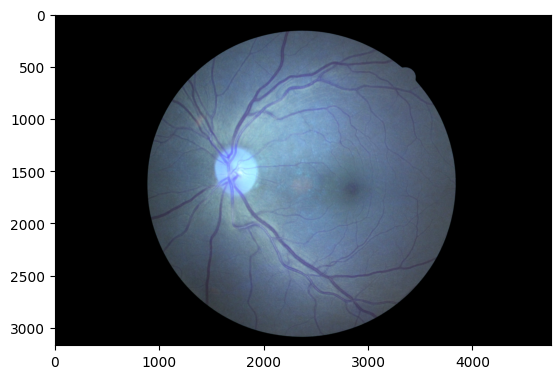

In [ ]:
paths_train= glob('/kaggle/input/diabetic-retinopathy-train-unzipped/train/*.jpeg')
image=cv2.imread(paths_train[0])
plt.imshow(image)

On constate une image avec une forme circulaire au milieu, entourée d'un bord noir. En général, toutes les images vont suivre cette forme.

On peut ensuite vérifier des images par niveau de maladie pour nous familiariser avec elles.

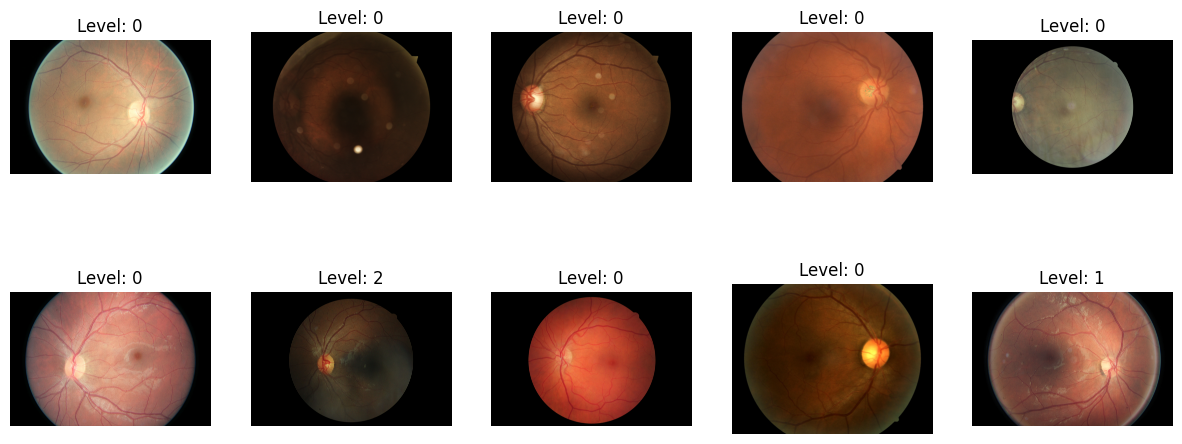

In [ ]:
# Afficher des images aléatoires de l'ensemble d'entraînement
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

samples = df_train.sample(10)

for ax, (_, row) in zip(axes.flat, samples.iterrows()):

    img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{row.image}.jpeg")

    ax.imshow(img)
    ax.set_title(f"Level: {row.level}")
    ax.axis("off")

plt.show()


On peut déjà voir qu'il y a d'énormes variations entre les images, même si elles appartiennent au même groupe. On constate des différences de taille, de niveau de luminosité, de couleur du cercle, de netteté, de niveau de zoom, entre autres.

Cela nous donne une indication sur la façon de transformer les images. On va devoir homogénéiser les images en les transformant, par exemple en coupant la bordure noire, en changeant la résolution des images vers une résolution commune et en normalisant la luminosité (avec l'aide du prétraitement d'images de Ben Graham).

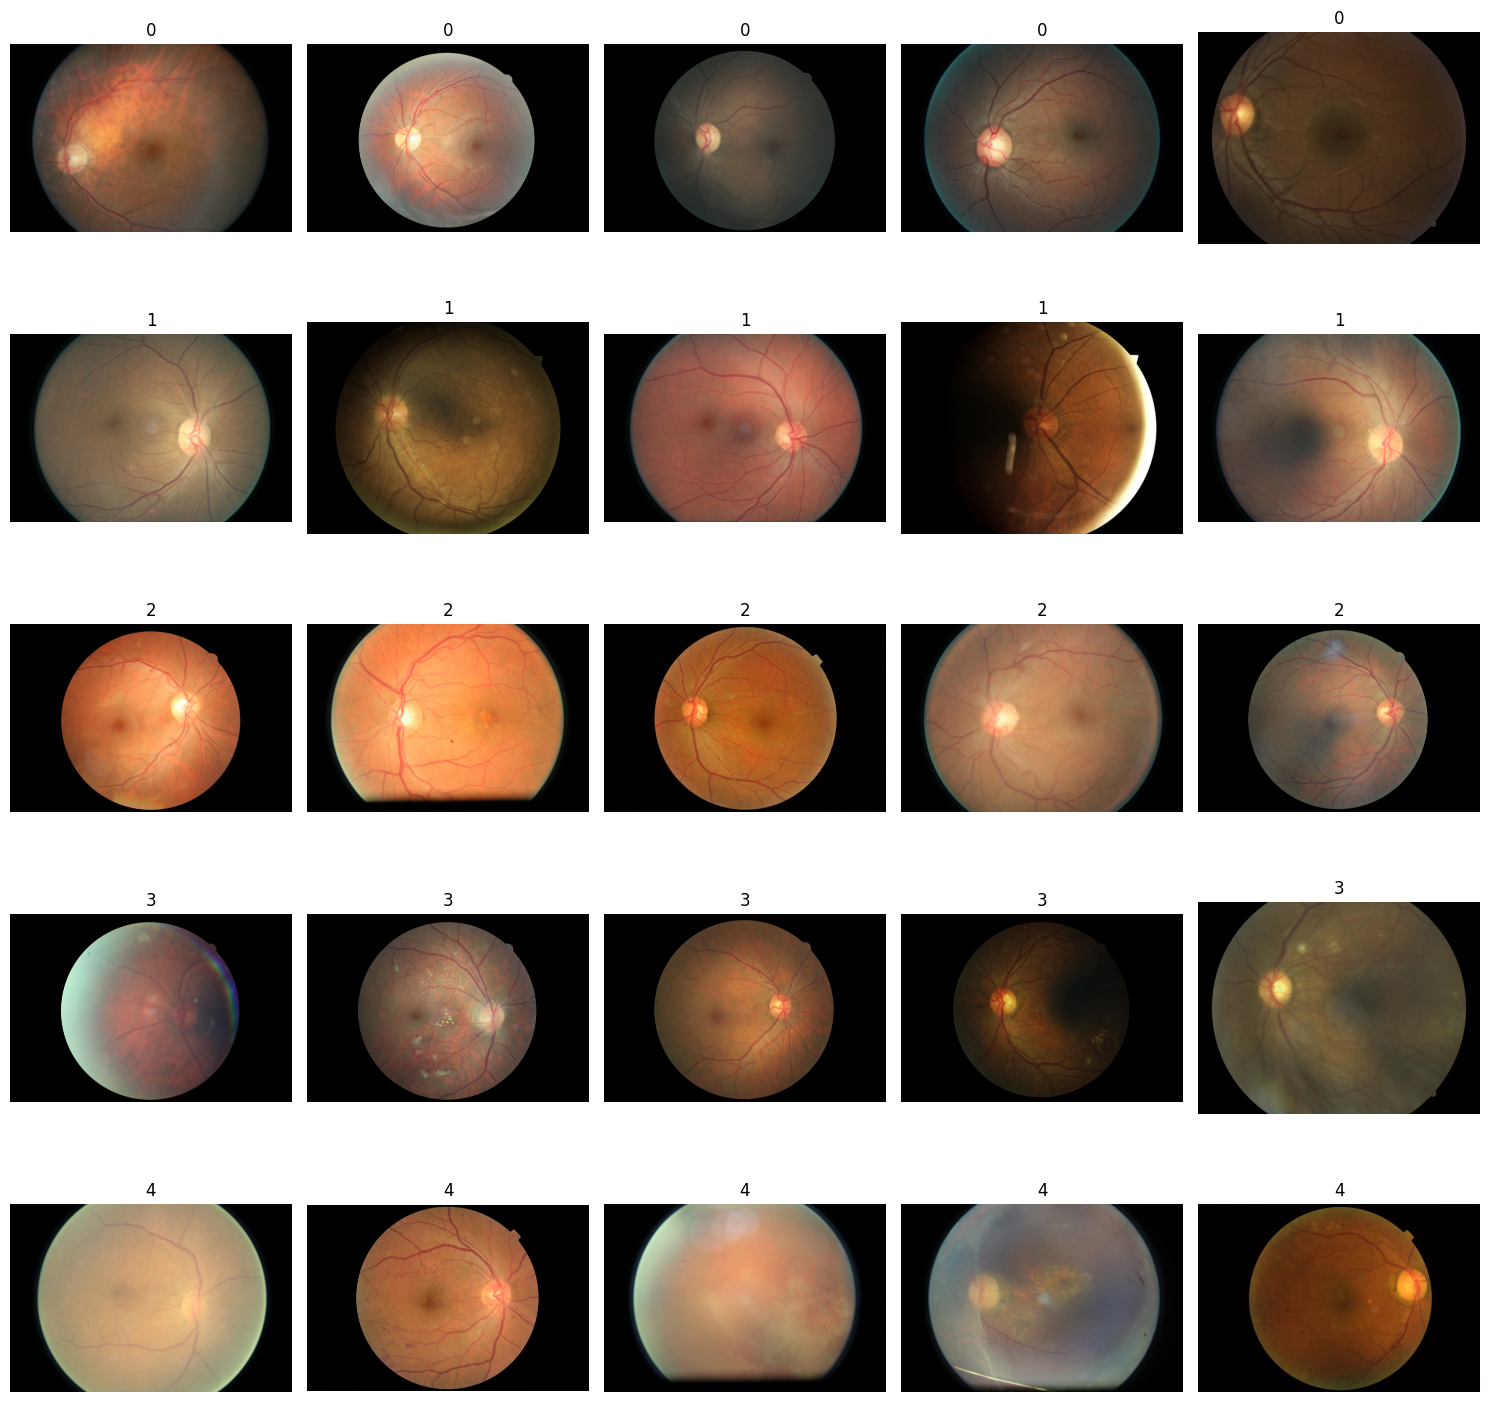

In [ ]:
# Exemples d'images par classe
fig, axes = plt.subplots(5,5, figsize=(15,15))

for level in range(5):

    samples = df_train[df_train.level == level].sample(5)

    for ax, (_, row) in zip(axes[level], samples.iterrows()):

        img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{row.image}.jpeg")

        ax.imshow(img)
        ax.set_title(level)
        ax.axis("off")

plt.tight_layout()
plt.show()


On constate aussi que les lésions qui déterminent le niveau de maladie de l'œil ne sont pas évidentes à première vue. Il y a des images du même groupe qui ont des lésions plus visibles que d'autres.

## Taille des images

Le modèle qu'on va utiliser a besoin d'images de même taille pour s'entraîner. On a vu précédemment que les images n'ont pas la même taille, donc on va approfondir un peu plus ce sujet.

In [ ]:
# Taille des images
sizes = []

# Pour les 500 premières images
for img_name in df_train.image[:500]:

# Pour toutes les images
#for img_name in df_train.image[:]:
    img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")
    sizes.append(img.size)

print(sizes[:10])
print("-----------------")

size_df = pd.DataFrame(sizes, columns=["width","height"])
print(size_df.describe())



[(4752, 3168), (4752, 3168), (2592, 1944), (2592, 1944), (4928, 3264), (4928, 3264), (3888, 2592), (3888, 2592), (3888, 2592), (3888, 2592)]
-----------------
             width       height
count   500.000000   500.000000
mean   3736.500000  2532.980000
std     801.749161   473.949986
min    1792.000000  1184.000000
25%    3456.000000  2304.000000
50%    3888.000000  2592.000000
75%    4288.000000  2848.000000
max    4928.000000  3264.000000


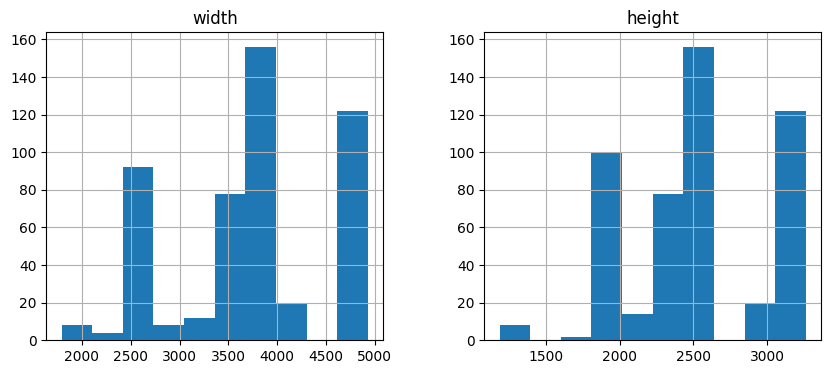

In [ ]:
size_df.hist(figsize=(10,4))
plt.show()

Avec le graphique et le tableau ci-dessus, on voit que les images sont très hétérogènes en taille. On a une largeur de 1792 à 4928 px (moyenne ≈ 3737) et une hauteur de 1184 à 3264 px (moyenne ≈ 2533), ce qui est une variation énorme. En conséquence, on va transformer toutes les images vers une taille commune de 512×512 dans la prochaine étape de prétraitement des images.

## Images corrompues

On doit aussi vérifier l'intégrité des images.

In [ ]:
bad_images = []

# Pour les 500 premières images
for img_name in df_train.image[:500]:

# Pour toutes les images
#for img_name in df_train.image[:]:

    try:
        img = Image.open(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")
        img.verify()

    except Exception:
        bad_images.append(img_name)

print(bad_images)

# Pas d'images défectueuses ou corrompues

[]


On n'a pas eu d'erreurs et on a une liste vide à la fin, ce qui démontre qu'il n'y a pas d'images corrompues dans notre base de données.

## Luminosité

C'est important aussi de voir le niveau de luminosité de chaque image, car cela va nous permettre d'entraîner notre modèle de façon plus efficace. Vu qu'on a déjà une indication qu'il y a des images très sombres, on va regarder la luminosité plus en détail.

In [ ]:
# Vérifier la luminosité des images. On convertit d'abord en niveaux de gris, puis on calcule la luminosité moyenne de l'image (échantillon = 500 premières images)

brightness = []

for img_name in df_train.image[:500]:
    
    img = cv2.imread(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    brightness.append(gray.mean())
    # Données prétraitées
print(brightness[:10])    

[np.float64(56.90911894088188), np.float64(24.79443948906149), np.float64(57.706481124256975), np.float64(58.32477304336229), np.float64(60.93454818006748), np.float64(63.62240173945999), np.float64(97.60623112663848), np.float64(87.658328252807), np.float64(43.37068323950236), np.float64(52.02923872678834)]


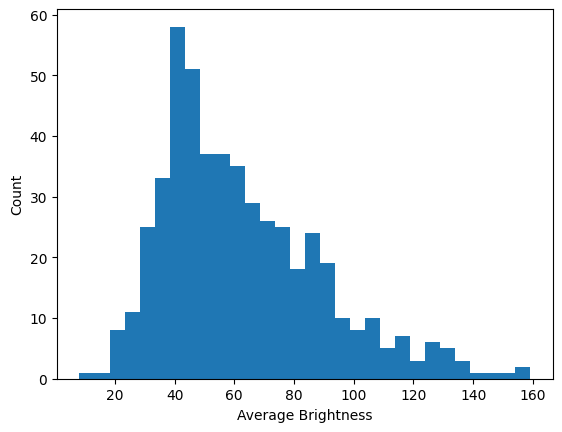

In [ ]:
# Afficher la luminosité
plt.hist(brightness, bins=30)
plt.xlabel("Average Brightness")
plt.ylabel("Count")
plt.show()

On constate une luminosité moyenne entre 30 et 90 avec une longue queue à droite, ce qui nous indique qu'il y a peu d'images tres claires. Cettes valeurs de luminosité incluient la bordure noire, mais ca confirme quand meme une forte hétérogénéité. On doit donc normaliser le niveau de luminosité des images. On va aussi utiliser le prétraitement d'images de Ben Graham à cet effet.

## Flou

On veut voir aussi la netteté des images. Pour ça, on va utiliser le laplacien, qui va détecter les bords présents dans les images. Une valeur faible nous indique une image peu nette. On le fait car il est important de ne pas avoir d'images peu nettes : elles peuvent cacher des lésions difficiles à voir et biaiser le modèle.

In [ ]:
# Vérifier le flou des images avec le laplacien
def blur_score(img):

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()


blur_scores = []

for img_name in df_train.image[:500]:

    img = cv2.imread(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")

    if img is None:
        continue

    score = blur_score(img)

    blur_scores.append(score)

In [ ]:
print(blur_scores[:50])    

[np.float64(11.920238129400062), np.float64(9.06666424875863), np.float64(14.18684661872508), np.float64(12.475991529928912), np.float64(7.3573514366684085), np.float64(7.192324497270499), np.float64(9.168894745423318), np.float64(9.831586679798153), np.float64(14.188539721776701), np.float64(15.937803640831815), np.float64(12.96814589366455), np.float64(17.769031234911992), np.float64(7.6575274402491225), np.float64(7.901143955940471), np.float64(12.236006822220522), np.float64(12.520478817531359), np.float64(94.27785824723043), np.float64(51.99864903531321), np.float64(21.093315575305937), np.float64(18.981660887567756), np.float64(6.123721133798118), np.float64(8.440228492683529), np.float64(45.84900650913315), np.float64(32.247946338679434), np.float64(5.040272820776038), np.float64(5.001630215296346), np.float64(9.439270718940985), np.float64(9.814938670780812), np.float64(22.59773578537301), np.float64(20.429160551872318), np.float64(8.87587449752), np.float64(8.256929212599742),

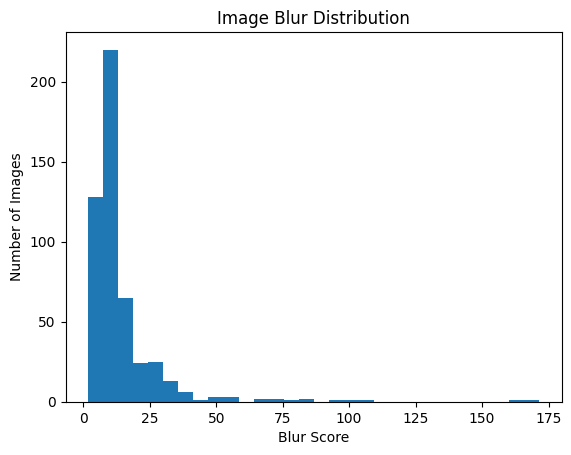

In [ ]:
plt.hist(blur_scores, bins=30)
plt.xlabel("Blur Score")
plt.ylabel("Number of Images")
plt.title("Image Blur Distribution")
plt.show()

On a des images qui sont plutôt peu nettes. On va transformer les images pour essayer de réduire cela, mais ce n'est pas aussi simple à corriger que la taille ou le niveau de luminosité. À cause de cela, on va ajouter une étape lors de l'entraînement du modèle pour créer un modèle plus robuste aux images peu nettes.

## Bordures noires

Finalement, on veut voir le pourcentage de l'image qui ne nous est pas utile, c'est-à-dire le pourcentage de l'image qui n'est que la bordure noire.

In [ ]:
# Vérifier les bordures noires
black_pixels = np.mean(gray < 10)

In [ ]:
black_percentages = []

for img_name in df_train.image[:500]:

    img = cv2.imread(f"/kaggle/input/diabetic-retinopathy-train-unzipped/train/{img_name}.jpeg")

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    black_percentages.append(np.mean(gray < 10))

print(black_percentages[:10])

[np.float64(0.5290212069134101), np.float64(0.5296205691170969), np.float64(0.364865540695016), np.float64(0.36481116318650614), np.float64(0.5024466285093583), np.float64(0.5023464108654826), np.float64(0.2503955269140883), np.float64(0.2604101175506783), np.float64(0.5255927545343697), np.float64(0.5254378580183408)]


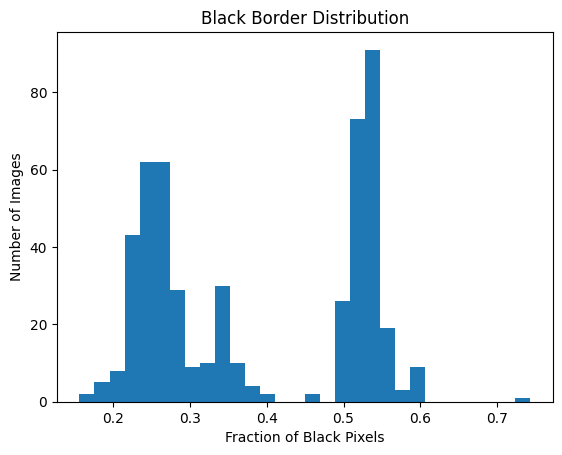

In [ ]:
plt.hist(black_percentages, bins=30)
plt.xlabel("Fraction of Black Pixels")
plt.ylabel("Number of Images")
plt.title("Black Border Distribution")
plt.show()

On constate que toutes les images possèdent une bordure noire importante. On voit aussi qu'il y a deux groupes différents, ce qui peut indiquer que deux appareils photo différents ont été utilisés pour capturer les images. On voit qu'entre 15 et 75 % des pixels sont noirs. À cause de cela, on va enlever la bordure noire dans la prochaine étape de prétraitement des images, pour éviter d'avoir une grande partie de notre image dédiée à quelque chose qui ne nous est pas utile.